# Redes Neuronales 2026
https://es.wikipedia.org/wiki/Perceptr%C3%B3n
---

# Guía de ejercicios N°9: *Perceptron simple* y *Perceptron* con una capa oculta
# Una neurona con dos entradas y `bias` estándar de PyTorch
## Implementación con PyTorch y `nn.Sequential`

En esta notebook utilizaremos una neurona con dos entradas:

$$
\mathbf{x}=(x_1,x_2),
$$

y el `bias` o (sesgo) estándar de `nn.Linear` <font color="green">(**b sesgo/bias aditivo) w1,w2 pesos. w1,w2,b son los parametros que la neurona debe aprender** <font>:

$$
h=w_1x_1+w_2x_2+b.
$$

Luego aplicaremos una función *sigmoide* <font color="green">(**derivable, sirve para optimizacion desenso por el gradiente)**<font color="green">:

$$
\hat y=\sigma(h)=\frac{1}{1+e^{-h}}.
$$

La primera parte contiene un **ejemplo completo resuelto para la compuerta OR**.

A partir de ese ejemplo, deberá repetir el procedimiento para:

1. intentar representar XOR con el mismo perceptrón simple;
2. analizar el resultado;
3. implementar una red con una capa oculta para representar XOR.

> La idea central de la actividad es distinguir entre **optimización** —cómo se ajustan los parámetros— y **capacidad de representación** —qué funciones puede representar una arquitectura.


## Objetivos

Al finalizar la actividad debería poder:

- construir un modelo sencillo con `nn.Sequential`;
- interpretar `nn.Linear(2,1)` y su `bias`;
- realizar un *forward pass*;
- calcular una función de costo;
- usar `loss.backward()` para obtener gradientes;
- actualizar parámetros mediante descenso por gradiente;
- entrenar con `torch.optim.SGD`;
- evaluar las cuatro configuraciones binarias;
- relacionar la frontera de decisión con $h=0$;
- comparar OR y XOR;
- implementar una red $2\to2\to1$ (red con una capa oculta).


# 1. Preparación del entorno


In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)
torch.set_printoptions(precision=4, sci_mode=False)


Versión de PyTorch: 2.15.0+cpu


# 2. Datos de entrada

Para dos variables binarias existen solamente cuatro configuraciones:

$$
(0,0),\quad(0,1),\quad(1,0),\quad(1,1).
$$



In [2]:
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y_or = torch.tensor([
    [0.],
    [1.],
    [1.],
    [1.]
])

print("X =")
print(X)

print("y_or =")
print(y_or)

print("\nX.shape =", X.shape)
print("y_or.shape =", y_or.shape)


X =
tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])
y_or =
tensor([[0.],
        [1.],
        [1.],
        [1.]])

X.shape = torch.Size([4, 2])
y_or.shape = torch.Size([4, 1])


## Interpretación de las dimensiones

`X.shape == (4,2)` significa:

- 4 ejemplos;
- 2 variables de entrada por ejemplo.

`y_or.shape == (4,1)` significa que existe una salida deseada por ejemplo.


# 3. Funciones auxiliares

Las siguientes funciones se utilizarán primero en el ejemplo OR y luego podrán reutilizarse en las actividades de XOR.


In [3]:
def graficar_puntos(X, y, titulo):
    Xn = X.detach().cpu().numpy()
    yn = y.detach().cpu().numpy().ravel()

    plt.figure(figsize=(5.5, 5))

    for clase, marcador in [(0, "o"), (1, "s")]:
        mask = yn == clase
        plt.scatter(
            Xn[mask, 0],
            Xn[mask, 1],
            s=150,
            marker=marcador,
            edgecolors="black",
            label=f"Clase {clase}"
        )

    plt.xlim(-0.3, 1.3)
    plt.ylim(-0.3, 1.3)
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


def crear_modelo_lineal(semilla=7):
    torch.manual_seed(semilla)

    # nn lineal funcion pre-activacion h. Y ese valor pasa por la funcion de activacion de tipo sigmoide
    return nn.Sequential(
        nn.Linear(2, 1),
        nn.Sigmoid()
    )


"""
def clases(modelo, X, umbral=0.5):
    with torch.no_grad():
        return (modelo(X) >= umbral).int()
"""


def entrenar(modelo, X, y, epocas=4000, eta=0.5):
    criterio = nn.MSELoss()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=eta)  #sigmoide

    historial = {
        "antes": [],
        "despues": []
    }

    for _ in range(epocas):
        # 1. Forward pass
        y_pred = modelo(X)

        # 2. Costo antes de actualizar
        loss_antes = 0.5 * criterio(y_pred, y)
        historial["antes"].append(loss_antes.item())

        # 3. Gradientes
        optimizador.zero_grad()
        loss_antes.backward()

        # 4. Actualización de parámetros
        optimizador.step()

        # 5. Costo después de actualizar
        with torch.no_grad():
            y_pred_despues = modelo(X)
            loss_despues = 0.5 * criterio(y_pred_despues, y)

        historial["despues"].append(loss_despues.item())

    return historial


def graficar_costos_antes_despues(historial, titulo):
    epocas = range(1, len(historial["antes"]) + 1)

    plt.figure(figsize=(7.5, 4.5))
    plt.plot(epocas, historial["antes"], label="Antes de actualizar")
    plt.plot(epocas, historial["despues"], "--", label="Después de actualizar")
    plt.xlabel("Época")
    plt.ylabel("Costo")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


def graficar_frontera_lineal(modelo, X, y, titulo):
    Xn = X.detach().cpu().numpy()
    yn = y.detach().cpu().numpy().ravel()

    w = modelo[0].weight.detach().flatten()
    b = modelo[0].bias.detach().item()

    plt.figure(figsize=(5.5, 5))

    for clase, marcador in [(0, "o"), (1, "s")]:
        mask = yn == clase
        plt.scatter(
            Xn[mask, 0],
            Xn[mask, 1],
            s=150,
            marker=marcador,
            edgecolors="black",
            label=f"Clase {clase}"
        )

    # Frontera: w1*x1 + w2*x2 + b = 0
    if abs(w[1].item()) > 1e-10:
        x1 = torch.linspace(-0.3, 1.3, 200)
        x2 = -(w[0] * x1 + b) / w[1]
        plt.plot(x1.numpy(), x2.numpy(), label="Frontera h=0")
    elif abs(w[0].item()) > 1e-10:
        x1_const = -b / w[0].item()
        plt.axvline(x1_const, label="Frontera h=0")

    plt.xlim(-0.3, 1.3)
    plt.ylim(-0.3, 1.3)
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


# 4. Ejemplo resuelto: compuerta OR

La tabla OR es:

| $x_1$ | $x_2$ | OR |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 1 |

Primero observaremos la geometría del problema.


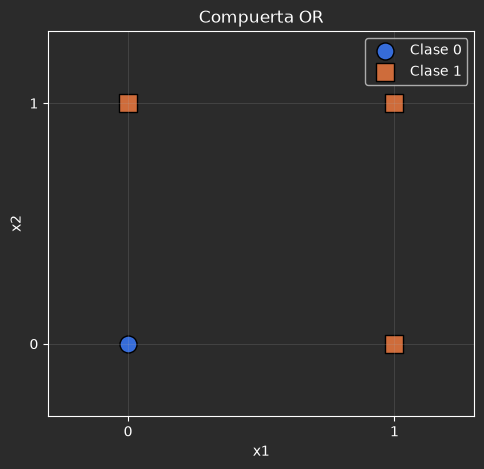

In [4]:
graficar_puntos(X, y_or, "Compuerta OR")


## 4.1. Construcción del *perceptron* simple

La arquitectura es:

```python
nn.Sequential(
    nn.Linear(2, 1),
    nn.Sigmoid()
)
```
```text
x1 ─────┐
        ├──> Linear(2,1, bias=True) ──> Sigmoid ──> ŷ
x2 ─────┘
```


`nn.Linear(2,1)` calcula:

$$
h=w_1x_1+w_2x_2+b.
$$

La sigmoide produce:

$$
\hat y=\sigma(h).
$$


In [5]:
modelo_or = crear_modelo_lineal(semilla=7)
print(modelo_or)


Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): Sigmoid()
)


## 4.2. Inspección de parámetros

`weight` contiene $w_1$ y $w_2$.

`bias` contiene $b$.


In [6]:
capa_lineal = modelo_or[0]

print("Pesos [w1, w2]:")
print(capa_lineal.weight)
print("Shape de weight:", capa_lineal.weight.shape)

print("\nBias b:")
print(capa_lineal.bias)
print("Shape de bias:", capa_lineal.bias.shape)


Pesos [w1, w2]:
Parameter containing:
tensor([[ 0.0494, -0.4260]], requires_grad=True)
Shape de weight: torch.Size([1, 2])

Bias b:
Parameter containing:
tensor([0.2252], requires_grad=True)
Shape de bias: torch.Size([1])


## 4.3. *Forward pass* inicial


In [7]:
with torch.no_grad():
    y_inicial_or = modelo_or(X)
    clases_iniciales_or = (y_inicial_or >= 0.5).int()

print("Salidas iniciales:")
print(y_inicial_or)

print("\nClases iniciales:")
print(clases_iniciales_or)


Salidas iniciales:
tensor([[0.5561],
        [0.4500],
        [0.5682],
        [0.4622]])

Clases iniciales:
tensor([[1],
        [0],
        [1],
        [0]], dtype=torch.int32)


## 4.4. Función de costo

Usaremos:

$$
E=
\frac{1}{2M}
\sum_{m=1}^{M}
\left(\hat y^{(m)}-y^{(m)}\right)^2.
$$

`nn.MSELoss()` calcula el promedio del error cuadrático. Multiplicamos por $0.5$ para mantener la misma convención utilizada en la derivaciones matemáticas usuales.


In [8]:
criterio = nn.MSELoss()

y_pred = modelo_or(X)
loss_or = 0.5 * criterio(y_pred, y_or)

print("Costo inicial para OR:", loss_or.item())


Costo inicial para OR: 0.13592258095741272


## 4.5. Cálculo de gradientes

`loss.backward()` calcula los gradientes respecto de todos los parámetros aprendibles.

Los gradientes de $w_1,w_2$ quedan en:

```python
modelo_or[0].weight.grad
```

y el gradiente de $b$ en:

```python
modelo_or[0].bias.grad
```


In [9]:
modelo_or.zero_grad()

y_pred = modelo_or(X)
loss_or = 0.5 * criterio(y_pred, y_or)
loss_or.backward()

print("Gradientes de los pesos:")
print(modelo_or[0].weight.grad)

print("\nGradiente del bias:")
print(modelo_or[0].bias.grad)


Gradientes de los pesos:
tensor([[-0.0599, -0.0675]])

Gradiente del bias:
tensor([-0.0596])


## 4.6. Una actualización manual

El descenso por gradiente utiliza:

$$
\theta_i
\leftarrow
\theta_i-
\eta\frac{\partial E}{\partial\theta_i}.
$$

Para modificar parámetros directamente utilizamos `torch.no_grad()`.


In [10]:
eta = 0.5

modelo_manual = crear_modelo_lineal(semilla=7)
criterio_manual = nn.MSELoss()

# Forward y backward
y_pred = modelo_manual(X)
loss_antes_manual = 0.5 * criterio_manual(y_pred, y_or)

modelo_manual.zero_grad()
loss_antes_manual.backward()

print("Costo antes:", loss_antes_manual.item())

with torch.no_grad():
    for parametro in modelo_manual.parameters():
        parametro -= eta * parametro.grad

with torch.no_grad():
    loss_despues_manual = 0.5 * criterio_manual(modelo_manual(X), y_or)

print("Costo después:", loss_despues_manual.item())


Costo antes: 0.13592258095741272
Costo después: 0.1301986575126648


## 4.7. Entrenamiento con SGD

En cada época:

1. hacemos el *forward pass*;
2. calculamos $E_{\mathrm{antes}}$;
3. calculamos gradientes;
4. actualizamos parámetros;
5. calculamos $E_{\mathrm{después}}$.


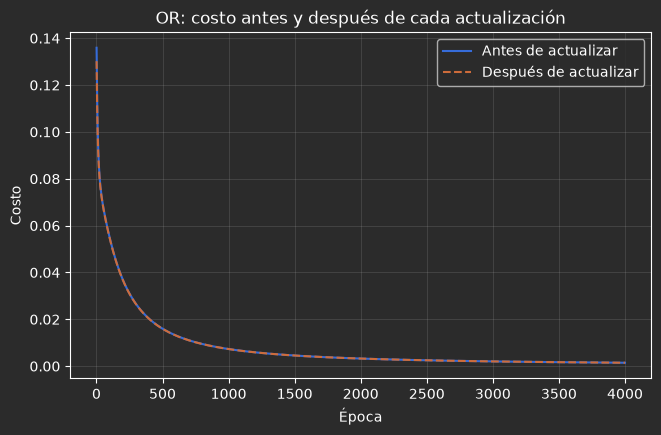

In [11]:
modelo_or = crear_modelo_lineal(semilla=7)
historial_or = entrenar(modelo_or, X, y_or, epocas=4000, eta=0.5)

graficar_costos_antes_despues(
    historial_or,
    "OR: costo antes y después de cada actualización"
)


## 4.8. Evaluación del modelo OR


In [12]:
with torch.no_grad():
    salidas_or = modelo_or(X)
    pred_or = (salidas_or >= 0.5).int()

aciertos_or = (pred_or == y_or.int()).sum().item()

print(" x1   x2   salida      predicción   correcta")
print("------------------------------------------------")

for i in range(len(X)):
    print(
        f" {int(X[i, 0])}    {int(X[i, 1])}    "
        f"{salidas_or[i].item():.4f}          "
        f"{pred_or[i].item()}            "
        f"{int(y_or[i].item())}"
    )

print(f"\nAciertos: {aciertos_or}/{len(X)}")
print("Costo final:", historial_or["despues"][-1])


 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.0813          0            0
 0    1    0.9495          1            1
 1    0    0.9495          1            1
 1    1    0.9997          1            1

Aciertos: 4/4
Costo final: 0.0014637877466157079


## 4.9. Frontera de decisión

Como:

$$
\sigma(0)=0.5,
$$

la frontera de decisión se encuentra en:

$$
h=0.
$$

Por lo tanto:

$$
w_1x_1+w_2x_2+b=0.
$$


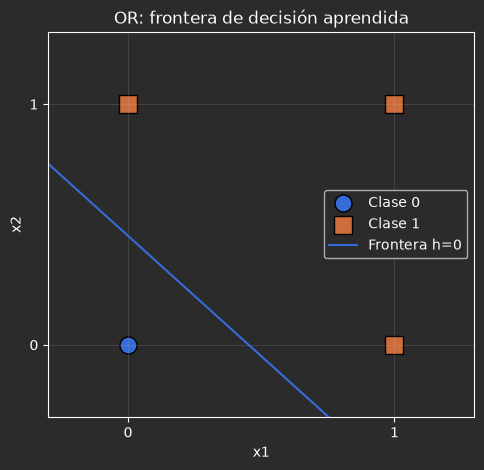

In [13]:
graficar_frontera_lineal(
    modelo_or,
    X,
    y_or,
    "OR: frontera de decisión aprendida"
)


# 5. Actividad guiada: XOR con el mismo perceptrón simple

Ahora deberá repetir los pasos del ejemplo OR utilizando la compuerta XOR, **sin modificar todavía la arquitectura**.


## Lista de tareas — XOR con perceptrón simple

1. Defina la tabla de verdad de XOR.
2. Grafique los cuatro puntos.
3. Cree un nuevo perceptrón simple.
4. Inspeccione los parámetros iniciales.
5. Realice el forward pass inicial.
6. Obtenga las clases usando el umbral $0.5$.
7. Calcule el costo inicial.
8. Calcule e inspeccione los gradientes.
9. Realice una actualización manual.
10. Entrene un modelo nuevo con SGD.
11. Grafique el costo antes y después de cada actualización.
12. Evalúe las cuatro configuraciones.
13. Calcule el número de aciertos.
14. Inspeccione los parámetros finales.
15. Grafique la frontera de decisión.
16. Repita el entrenamiento con distintas semillas.
17. Compare la geometría de OR y XOR.
18. Formule una conclusión sobre la capacidad de la arquitectura.


## Tarea 1 — Definir las salidas de XOR

XOR vale 1 cuando las dos entradas son diferentes.

Construya `y_xor` con `shape == (4,1)`.


In [14]:
# TODO 1
# Defina y_xor usando torch.tensor(...)

# y_xor = ...

X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y_xor = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])


# print(y_xor)
# print("shape =", y_xor.shape)


## Tarea 2 — Graficar XOR

Use la función `graficar_puntos(...)`.

Antes de entrenar, observe la disposición de las dos clases.


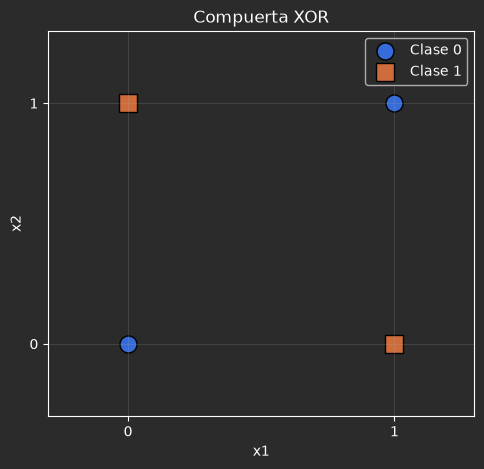

In [15]:
# TODO 2
graficar_puntos(X, y_xor, "Compuerta XOR")


## Tarea 3 — Crear un nuevo perceptrón simple

No reutilice el modelo entrenado para OR.

Use la misma arquitectura:

```python
nn.Linear(2, 1)
nn.Sigmoid()
```


In [16]:
# TODO 3
modelo_xor = crear_modelo_lineal(semilla=7)
print(modelo_xor)


Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): Sigmoid()
)


## Tarea 4 — Inspeccionar parámetros iniciales

Imprima los pesos, el `bias` y sus `shape`.

Identifique $w_1$, $w_2$ y $b$.


In [17]:
# TODO 4
capa_lineal = modelo_xor[0]

print("Pesos [w1, w2]:")
print(capa_lineal.weight)
print("Shape de weight:", capa_lineal.weight.shape)

print("\nBias b:")
print(capa_lineal.bias)
print("Shape de bias:", capa_lineal.bias.shape)


Pesos [w1, w2]:
Parameter containing:
tensor([[ 0.0494, -0.4260]], requires_grad=True)
Shape de weight: torch.Size([1, 2])

Bias b:
Parameter containing:
tensor([0.2252], requires_grad=True)
Shape de bias: torch.Size([1])


## Tarea 5 — *Forward pass* inicial

Obtenga:

- las salidas continuas;
- las clases usando el umbral $0.5$.

Compare con la tabla de verdad de XOR.


In [18]:
# TODO 5
with torch.no_grad():
    y_inicial_xor = modelo_xor(X)
    clases_iniciales_xor = (y_inicial_xor >= 0.5).int()

print("Salidas iniciales:")
print(y_inicial_xor)

print("\nClases iniciales:")
print(clases_iniciales_xor)


Salidas iniciales:
tensor([[0.5561],
        [0.4500],
        [0.5682],
        [0.4622]])

Clases iniciales:
tensor([[1],
        [0],
        [1],
        [0]], dtype=torch.int32)


## Tarea 6 — Costo inicial

Use la misma expresión utilizada para OR:

$$
E=
\frac{1}{2M}
\sum_m
\left(\hat y^{(m)}-y^{(m)}\right)^2.
$$


In [19]:
criterio = nn.MSELoss()

y_pred = modelo_xor(X)
loss_xor = 0.5 * criterio(y_pred, y_xor)

print("Costo inicial para OR:", loss_xor.item())


Costo inicial para OR: 0.12647753953933716


## Tarea 7 — Gradientes

Repita:

```python
modelo_xor.zero_grad()
...
loss_xor.backward()
```

e inspeccione:

```python
modelo_xor[0].weight.grad
modelo_xor[0].bias.grad
```


In [20]:
modelo_xor.zero_grad()

y_pred = modelo_xor(X)
loss_xor = 0.5 * criterio(y_pred, y_xor)
loss_xor.backward()

print("Gradientes de los pesos:")
print(modelo_xor[0].weight.grad)

print("\nGradiente del bias:")
print(modelo_xor[0].bias.grad)


Gradientes de los pesos:
tensor([[ 0.0022, -0.0053]])

Gradiente del bias:
tensor([0.0025])


## Tarea 8 — Actualización manual

Actualice los parámetros dentro de:

```python
with torch.no_grad():
```

y vuelva a calcular el costo.

**Pregunta:** ¿disminuyó el costo después del paso?


In [21]:
eta = 0.5

modelo_manual = crear_modelo_lineal(semilla=7)
criterio_manual = nn.MSELoss()

# Forward y backward
y_pred = modelo_manual(X)
loss_antes_manual = 0.5 * criterio_manual(y_pred, y_xor)

modelo_manual.zero_grad()
loss_antes_manual.backward()

print("Costo antes:", loss_antes_manual.item())

with torch.no_grad():
    for parametro in modelo_manual.parameters():
        parametro -= eta * parametro.grad

with torch.no_grad():
    loss_despues_manual = 0.5 * criterio_manual(modelo_manual(X), y_xor)

print("Costo después:", loss_despues_manual.item())


Costo antes: 0.12647753953933716
Costo después: 0.1264578402042389


## Tarea 9 — Entrenamiento con SGD

Cree un modelo nuevo y use `entrenar(...)`.

Como punto de partida:

```python
epocas=500
eta=0.5
```

Luego puede experimentar con más épocas.


In [22]:
modelo_xor = crear_modelo_lineal(semilla=7)
historial_xor = entrenar(modelo_xor, X, y_xor, epocas=4000, eta=0.5)



## Tarea 10 — Graficar el costo

Analice:

- ¿disminuye al principio?
- ¿se estabiliza?
- ¿la diferencia entre $E_{\mathrm{antes}}$ y $E_{\mathrm{después}}$ se hace pequeña?


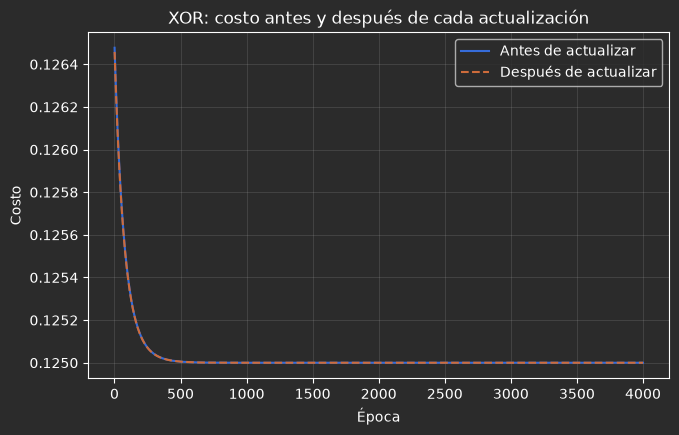

In [23]:
graficar_costos_antes_despues(
    historial_xor,
    "XOR: costo antes y después de cada actualización"
)


## Tarea 11 — Evaluación de las cuatro entradas

Muestre para cada ejemplo:

```text
x1   x2   salida   predicción   valor correcto
```

Calcule también la cantidad de aciertos.

No observe solamente las clases: examine los valores continuos $\hat y$.


In [24]:
# TODO 11
with torch.no_grad():
    salidas_xor = modelo_xor(X)
    pred_xor = (salidas_xor >= 0.5).int()

aciertos_xor = (pred_xor == y_xor.int()).sum().item()

print(" x1   x2   salida      predicción   correcta")
print("------------------------------------------------")

for i in range(len(X)):
    print(
        f" {int(X[i, 0])}    {int(X[i, 1])}    "
        f"{salidas_xor[i].item():.4f}          "
        f"{pred_xor[i].item()}            "
        f"{int(y_xor[i].item())}"
    )

print(f"\nAciertos: {aciertos_xor}/{len(X)}")
print("Costo final:", historial_xor["despues"][-1])

 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.5000          1            0
 0    1    0.5000          1            1
 1    0    0.5000          1            1
 1    1    0.5000          1            0

Aciertos: 2/4
Costo final: 0.125


## Tarea 12 — Parámetros finales y frontera (XOR NO ES LINEALMENTE SEPARABLE NUNCA VA A ANDAR)

Imprima:

$$
w_1,\quad w_2,\quad b.
$$

Luego grafique la frontera:

$$
w_1x_1+w_2x_2+b=0.
$$

**Pregunta:** ¿una única recta puede separar correctamente las dos clases de XOR?


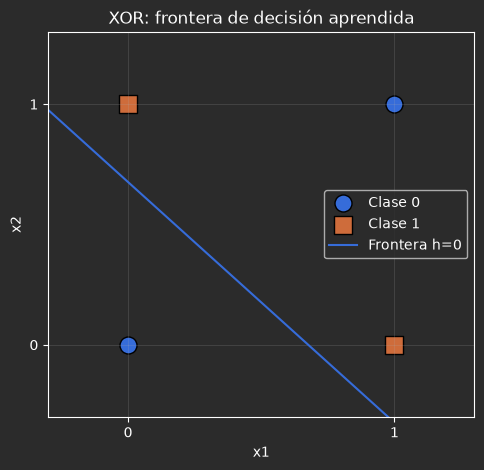

In [25]:
# TODO 12
# Inspeccione los parámetros finales y use graficar_frontera_lineal(...).
graficar_frontera_lineal(
    modelo_xor,
    X,
    y_xor,
    "XOR: frontera de decisión aprendida"
)

## Tarea 13 — Distintas inicializaciones

Repita el entrenamiento con varias semillas, por ejemplo:

```python
[1, 7, 15, 25]
```

Para cada caso registre:

- costo final;
- salidas continuas;
- predicciones;
- número de aciertos.

**Pregunta:** ¿cambiar la inicialización modifica la capacidad de representación del modelo?


In [26]:
# TODO 13
semillas = [1, 7, 15, 25]
for semilla in semillas:
    modelo_xor = crear_modelo_lineal(semilla=semilla)
    historial_xor = entrenar(modelo_xor, X, y_xor, epocas=4000, eta=0.5)

    with torch.no_grad():
        salidas_xor = modelo_xor(X)
        pred_xor = (salidas_xor >= 0.5).int()

    aciertos_xor = (pred_xor == y_xor.int()).sum().item()

    print(" x1   x2   salida      predicción   correcta")
    print("------------------------------------------------")

    for i in range(len(X)):
        print(
            f" {int(X[i, 0])}    {int(X[i, 1])}    "
            f"{salidas_xor[i].item():.4f}          "
            f"{pred_xor[i].item()}            "
            f"{int(y_xor[i].item())}"
        )

    print(f"\nAciertos: {aciertos_xor}/{len(X)}")
    print("Costo final:", historial_xor["despues"][-1])



 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.5000          1            0
 0    1    0.5000          1            1
 1    0    0.5000          1            1
 1    1    0.5000          1            0

Aciertos: 2/4
Costo final: 0.125
 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.5000          1            0
 0    1    0.5000          1            1
 1    0    0.5000          1            1
 1    1    0.5000          1            0

Aciertos: 2/4
Costo final: 0.125
 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.5000          1            0
 0    1    0.5000          1            1
 1    0    0.5000          1            1
 1    1    0.5000          1            0

Aciertos: 2/4
Costo final: 0.125
 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.5000 

# 6. Análisis de la separabilidad lineal de XOR

Use la condición:

$$
h=w_1x_1+w_2x_2+b.
$$

Para clase 1:

$$
h\geq0.
$$

Para clase 0:

$$
h<0.
$$

Escriba una condición para cada punto:

$$
(0,0),\quad(0,1),\quad(1,0),\quad(1,1).
$$

Luego responda:

1. ¿pueden satisfacerse simultáneamente las cuatro condiciones?
2. ¿el problema observado se debe a que SGD "no funciona"?
3. ¿aumentar el número de épocas cambia la familia de funciones que puede representar una sola neurona?
4. NOTAR QUE LO QUE LE EXIJO A b EN EL SISTEMA ES ABSURDO POR ESO UNCA VA A ANDAR CON UNA SOLA NEURONA.
4. ![image.png](image.png)

# Parte 2:
# *Perceptron* con una capa oculta

# 7. Actividad guiada: XOR con una capa oculta

Ahora **aumentaremos la capacidad del modelo**.

Utilizaremos una red:

$$
2\to2\to1.
$$

En PyTorch:

```python
nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)
```

La primera sigmoide actúa **elemento a elemento** sobre las dos neuronas ocultas.

El esquema de entrenamiento seguirá siendo el mismo que en OR:

$$
\text{forward}
\rightarrow
\text{costo}
\rightarrow
\text{backward}
\rightarrow
\text{actualización}.
$$


## Lista de tareas — XOR con perceptrón multicapa

1. Construya la red $2\to2\to1$.
2. Imprima el modelo e identifique sus componentes.
3. Inspeccione `weight` y `bias` de las dos capas lineales.
4. Cuente los parámetros aprendibles.
5. Realice un forward pass inicial.
6. Calcule el costo inicial.
7. Calcule los gradientes de ambas capas.
8. Entrene la red con la misma función `entrenar(...)`.
9. Grafique el costo.
10. Evalúe las cuatro entradas XOR.
11. Calcule el número de aciertos.
12. Compare las salidas con las del perceptrón simple.
13. Grafique la región de decisión.
14. Compare la frontera multicapa con la frontera lineal.
15. Formule una conclusión sobre el efecto de la capa oculta.


## Tarea 14 — Construir la red multicapa

Cree `modelo_mlp`.

Puede usar una semilla para reproducibilidad.


In [27]:
torch.manual_seed(7)

modelo_mlp = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)

print(modelo_mlp)


Sequential(
  (0): Linear(in_features=2, out_features=2, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=2, out_features=1, bias=True)
  (3): Sigmoid()
)


## Tarea 15 — Inspeccionar parámetros

Las capas lineales son:

```python
modelo_mlp[0]
modelo_mlp[2]
```

Para ambas inspeccione:

- `weight`;
- `weight.shape`;
- `bias`;
- `bias.shape`.

Luego cuente todos los parámetros aprendibles.

Puede usar:

```python
sum(p.numel() for p in modelo_mlp.parameters())
```


In [39]:
# Inspeccione parámetros y cuente cuántos hay.
capa_lineal1 = modelo_mlp[0]
print("----------------------------------- CAPA modelo_mlp[0] -----------------------------------")

print("Pesos [w1, w2]:")
print(capa_lineal1.weight)
print("Shape de weight:", capa_lineal1.weight.shape)

print("\nBias b:")
print(capa_lineal1.bias)
print("Shape de bias:", capa_lineal1.bias.shape)

print("----------------------------------- CAPA modelo_mlp[2] -----------------------------------")

capa_lineal2 = modelo_mlp[2]

print("Pesos [w1, w2]:")
print(capa_lineal2.weight)
print("Shape de weight:", capa_lineal2.weight.shape)

print("\nBias b:")
print(capa_lineal2.bias)
print("Shape de bias:", capa_lineal2.bias.shape)

print(f"{sum(p.numel() for p in modelo_mlp.parameters())}")

----------------------------------- CAPA modelo_mlp[0] -----------------------------------
Pesos [w1, w2]:
Parameter containing:
tensor([[ 0.4968,  0.5020],
        [ 0.0720, -0.3015]], requires_grad=True)
Shape de weight: torch.Size([2, 2])

Bias b:
Parameter containing:
tensor([-0.4153, -0.0777], requires_grad=True)
Shape de bias: torch.Size([2])
----------------------------------- CAPA modelo_mlp[2] -----------------------------------
Pesos [w1, w2]:
Parameter containing:
tensor([[-0.1990,  0.3117]], requires_grad=True)
Shape de weight: torch.Size([1, 2])

Bias b:
Parameter containing:
tensor([-0.6038], requires_grad=True)
Shape de bias: torch.Size([1])
9


## Tarea 16 — Forward pass inicial y costo

Evalúe la red multicapa sobre las cuatro entradas XOR.

Obtenga:

- salidas continuas;
- clases con umbral $0.5$;
- costo inicial.


In [29]:
# TODO 16
with torch.no_grad():
    y_inicial_xor = modelo_mlp(X)
    clases_iniciales_xor = (y_inicial_xor >= 0.5).int()

print("Salidas iniciales:")
print(y_inicial_xor)

print("\nClases iniciales:")
print(clases_iniciales_xor)

criterio = nn.MSELoss()
y_pred = modelo_mlp(X)
loss_xor = 0.5 * criterio(y_pred, y_xor)

print("Costo inicial para OR:", loss_xor.item())



Salidas iniciales:
tensor([[0.4324],
        [0.4448],
        [0.4337],
        [0.4463]])

Clases iniciales:
tensor([[0],
        [0],
        [0],
        [0]], dtype=torch.int32)
Costo inicial para OR: 0.12687496840953827


## Tarea 17 — Gradientes de ambas capas

Después de `loss.backward()`, inspeccione:

```python
modelo_mlp[0].weight.grad
modelo_mlp[0].bias.grad
modelo_mlp[2].weight.grad
modelo_mlp[2].bias.grad
```

Observe que autograd calcula gradientes para todos los parámetros que participaron en el forward pass.


In [30]:
# TODO 17
# Calcule e inspeccione los gradientes de ambas capas.
modelo_mlp.zero_grad()

y_pred = modelo_mlp(X)
loss_xor = 0.5 * criterio(y_pred, y_xor)
loss_xor.backward()

print("Gradientes de los pesos:")
print(modelo_mlp[0].weight.grad)
print(modelo_mlp[2].weight.grad)

print("\nGradiente del bias:")
print(modelo_mlp[0].bias.grad)
print(modelo_mlp[2].bias.grad)


Gradientes de los pesos:
tensor([[ 0.0010,  0.0005],
        [-0.0004, -0.0003]])
tensor([[-0.0055, -0.0079]])

Gradiente del bias:
tensor([ 0.0014, -0.0007])
tensor([-0.0149])


## Tarea 18 — Entrenamiento

Puede reutilizar directamente `entrenar(...)`.

Como punto de partida pruebe:

```python
epocas=6000
eta=1.0
```

Si el resultado no es satisfactorio, experimente con la semilla, las épocas o la tasa de aprendizaje.


In [60]:
# TODO 18
# Cree un modelo multicapa nuevo y entrénelo sobre XOR.
#
# modelo_mlp = ...
# historial_mlp = entrenar(modelo_mlp, X, y_xor, epocas=6000, eta=1.0)
modelo_mlp = modelo_mlp = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)
historial_mlp = entrenar(modelo_mlp, X, y_xor, epocas=6500,
                         eta=0.5)  # SI PONGO 8000 EPOCAS ME DA RARO!!!!!! (10000 ME DA BIEN, 6000 TAMBIEN, 60000 TAMBIEN)


## Tarea 19 — Costo y evaluación

Grafique el historial y luego informe:

- las cuatro salidas continuas;
- las predicciones;
- los valores correctos;
- el número de aciertos;
- el costo final.

Compare estos resultados con el perceptrón simple.


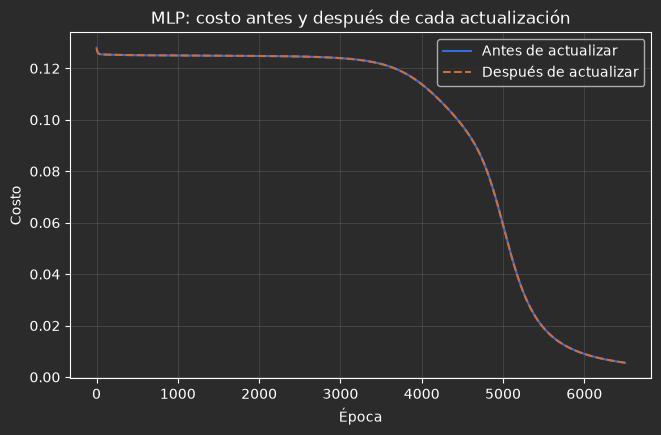

In [61]:
# TODO 19
# Grafique el costo y evalúe las cuatro entradas.
graficar_costos_antes_despues(
    historial_mlp,
    "MLP: costo antes y después de cada actualización"
)


## Tarea 20 — Región de decisión

El color del gráfico deberá representar la salida continua:

$$
\hat y(x_1,x_2).
$$

La curva:

$$
\hat y=0.5
$$

será la frontera de decisión.

Complete la función siguiente.


 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.1374          0            0
 0    1    0.6896          1            1
 1    0    0.6888          1            1
 1    1    0.4364          0            0

Aciertos: 4/4
Costo final: 0.05031190067529678


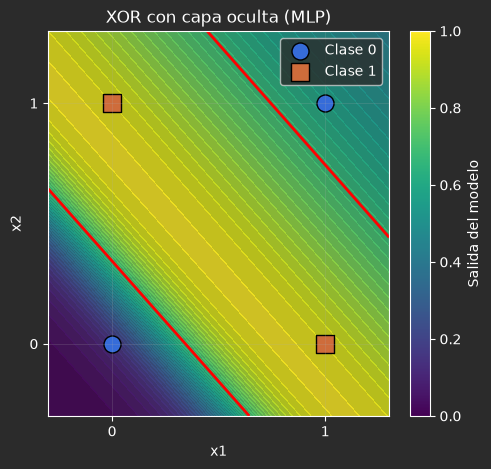

 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.0484          0            0
 0    1    0.9731          1            1
 1    0    0.9735          1            1
 1    1    0.9944          1            1

Aciertos: 4/4
Costo final: 0.0004755862755700946


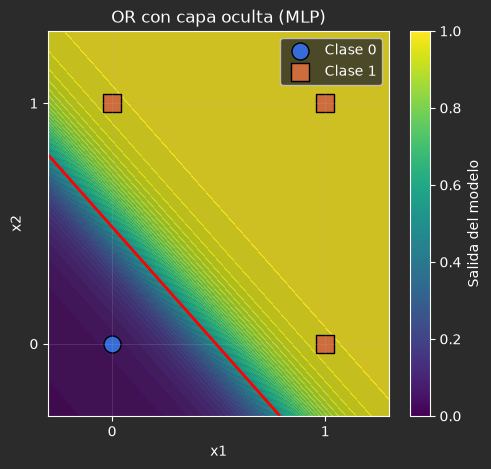

 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.0032          0            0
 0    1    0.0352          0            0
 1    0    0.0337          0            0
 1    1    0.9408          1            1

Aciertos: 4/4
Costo final: 0.0007360709132626653


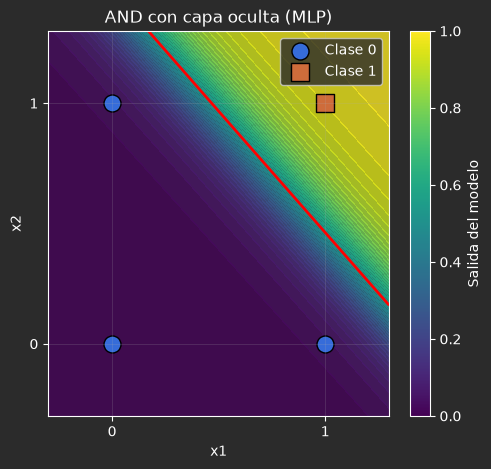

0

In [78]:
# TODO 20

def graficar_region_decision(modelo, X_p, y_p, titulo):
    # 1. Crear una grilla de puntos en el plano.
    eje = torch.linspace(-0.3, 1.3, 180)
    xx, yy = torch.meshgrid(eje, eje, indexing="xy")

    puntos = torch.stack([xx.ravel(), yy.ravel()], dim=1)

    # 2. Entrenar el modelo.
    historial = entrenar(modelo, X_p, y_p, epocas=6500,
                         eta=0.5)

    # 3. Evaluar el modelo sobre toda la grilla.
    with torch.no_grad():
        zz = modelo(puntos)
        zz = zz.reshape(xx.shape)

        # Evaluar también los puntos originales.
        salidas = modelo(X_p)
        predicciones_mlp = (salidas >= 0.5).int()

    aciertos_mlp = (predicciones_mlp == y_p.int()).sum().item()

    print(" x1   x2   salida      predicción   correcta")
    print("------------------------------------------------")

    for i in range(len(X_p)):
        print(
            f" {int(X_p[i, 0])}    {int(X_p[i, 1])}    "
            f"{salidas[i].item():.4f}          "
            f"{predicciones_mlp[i].item()}            "
            f"{int(y_p[i].item())}"
        )

    print(f"\nAciertos: {aciertos_mlp}/{len(X_p)}")
    print("Costo final:", historial["despues"][-1])

    # 4. Preparar los puntos originales.
    Xn = X_p.detach().cpu().numpy()
    yn = y_p.detach().cpu().numpy().ravel()

    xx_np = xx.numpy()
    yy_np = yy.numpy()
    zz_np = zz.numpy()

    # 5. Graficar.
    plt.figure(figsize=(5.5, 5))

    # Región de decisión.
    plt.contourf(
        xx_np, yy_np, zz_np,
        levels=50,
        cmap="viridis",
        alpha=0.8
    )

    # Frontera de decisión (salida = 0.5).
    plt.contour(
        xx_np, yy_np, zz_np,
        levels=[0.5],
        colors="red",
        linewidths=2
    )

    # 6. Superponer los puntos originales.
    for clase, marcador in [(0, "o"), (1, "s")]:
        mask = yn == clase

        plt.scatter(
            Xn[mask, 0],
            Xn[mask, 1],
            s=150,
            marker=marcador,
            edgecolors="black",
            label=f"Clase {clase}"
        )

    # 7. Configuración del gráfico.
    plt.xlim(-0.3, 1.3)
    plt.ylim(-0.3, 1.3)
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.colorbar(label="Salida del modelo")

    plt.show()
    return 0


torch.manual_seed(7)

modelo_in_mlpXOR = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)

graficar_region_decision(modelo_in_mlpXOR, X, y_xor, "XOR con capa oculta (MLP)")

modelo_in_mlpOR = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)
graficar_region_decision(modelo_in_mlpOR, X, y_or, "OR con capa oculta (MLP)")

y_AND = torch.tensor([
    [0.],
    [0.],
    [0.],
    [1.]
])
modelo_in_mlpAND = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)
graficar_region_decision(modelo_in_mlpAND, X, y_AND, "AND con capa oculta (MLP)")


In [ ]:
#Entrenar un modelo no garantiza que exista una solución dentro de la arquitectura elegida

# 8. Comparación final

Complete la tabla:

| Aspecto | Perceptrón simple | Red con capa oculta |
|---|-------------------|---------------------|
| Entradas | 2                 | 2                   |
| Capa oculta | No                | Sí                  |
| Número de parámetros | 2                 | 4                   |
| Tipo de frontera en el plano original | LINEAL            | NO LINEAL           |
| ¿Representa OR? | SI                | SI                  |
| ¿Representa XOR? | NO                | SI                  |

## Preguntas de cierre

1. ¿El descenso por gradiente consiguió disminuir el costo en el perceptrón simple aplicado a XOR?
2. ¿Por qué eso no implica necesariamente una clasificación perfecta?
3. ¿Por qué más épocas no solucionan una limitación de representación?
4. ¿Qué aporta la capa oculta?
5. ¿Qué papel cumple la no linealidad introducida por `nn.Sigmoid()`?
6. ¿Qué diferencias observa entre la frontera lineal y la región de decisión del modelo multicapa?
